# Predicción de Pokémon legendarios

## Definición del problema
- **Target:** `is_legendary` (1 = legendario, 0 = no legendario)
- **Tipo de problema:** clasificación binaria
- **Features:** stats de combate (hp, attack, defense, sp_attack, sp_defense, speed), altura, peso, generación, base_happiness y tipos (codificados como dummies).
- **¿Por qué los datos podrían servir?** En el EDA de la Tarea 1 observamos que los legendarios tienen stats de combate considerablemente más altos que el resto. Además, la mayoría de los no legendarios tiene base_happiness = 70, mientras que los legendarios suelen tener valores distintos. Esto sugiere que las features contienen información crucial que separa ambas clases.
- **Algoritmo:** Random Forest (bagging). Lo elegimos porque captura relaciones no lineales entre features, un legendario se caracteriza por tener varios stats altos a la vez, no necesita escalar los datos, acepta NaN de forma nativa y, al promediar muchos árboles entrenados con muestras bootstrap distintas, reduce el sobreajuste que tendría un árbol de decisión individual.

In [1]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

pd.set_option('display.max_columns', 100)
pd.set_option('display.max_rows', 100)
pd.set_option('display.max_colwidth', 100)


font = {'size'   : 16}
matplotlib.rc('font', **font)
matplotlib.rc('xtick', labelsize=14) 
matplotlib.rc('ytick', labelsize=14) 
matplotlib.rcParams.update({'figure.autolayout': False})
matplotlib.rcParams['figure.dpi'] = 300

In [2]:
PokemonSet = pd.read_csv('pokemon.csv')
target = PokemonSet['is_legendary']

In [3]:
PokemonSet['capture_rate'] = pd.to_numeric(PokemonSet['capture_rate'], errors='coerce')

PokemonSet['capture_rate'] = (
    PokemonSet['capture_rate']
    .astype(str)
    .str.extract(r'(\d+)', expand=False)
    .astype('Int64')
)

## Filtrado de Features

Para que el algoritmo realice un mejor trabajo, filtramos los features que tiene el DataSet. En este caso eliminamos los siguientes features que no aportan información relevante (según criterio propio):
- name
- japanese_name
- pokedex_number
- classification
- against_? 

Además, debido a que abilities es un string que contiene una o más habilidades por pokemones, es una feature un poco más difícil de trabajar, por lo que optamos por eliminarla del DataSet:
- abilities

También eliminamos el feature que nos dice directamente si el pokemon es legendario (pero se utilizará para validar los resultados, por eso se guardo la variable 'y' antes):
- is_legendary

Eliminamos los siguientes 5 features debido a que en el trabajo anterior se determinó que estas están directamente relacionadas con los pokemones legendarios (concentran a los legendarios dentro de unos rangos pequeños), evitando así hacer "trampa" con el modelo y determinar si es que se puede predecir correctamente utilizando las demás features:
- capture_rate
- percentage_male
- base_egg_steps 
- experience_growth
- base_total

En un anexo al final del notebook se demuestra que estas features generan un modelo que logra predecir de forma perfecta los pokemones legendarios, por lo que para probar mejor distintas formas de trabajar este DataSet se restringen las features dominantes, dejando únicamente base_happiness como otra feature dominante posible a eliminar, pero que no resulta tan influyente como el resto.

In [4]:
PokemonSet = PokemonSet.drop(['name', 
                            'japanese_name', 
                            'pokedex_number',
                            'classfication',
                            'against_fire',
                            'against_water',
                            'against_electric',
                            'against_grass',
                            'against_ice',
                            'against_fight',
                            'against_poison',
                            'against_ground',
                            'against_flying',
                            'against_psychic',
                            'against_bug',
                            'against_rock',
                            'against_ghost',
                            'against_dragon',
                            'against_dark',
                            'against_steel',
                            'against_fairy',
                            'against_normal',
                            'is_legendary',
                            'capture_rate',
                            'percentage_male',
                            'base_egg_steps',
                            'abilities',
                            'experience_growth',
                            'base_total'],
                            axis=1)

PokemonSet

,attack,base_happiness,defense,height_m,hp,sp_attack,sp_defense,speed,type1,type2,weight_kg,generation
0,49,70,49,0.7,45,65,65,45,grass,poison,6.9,1
1,62,70,63,1.0,60,80,80,60,grass,poison,13.0,1
2,100,70,123,2.0,80,122,120,80,grass,poison,100.0,1
3,52,70,43,0.6,39,60,50,65,fire,NaN,8.5,1
4,64,70,58,1.1,58,80,65,80,fire,NaN,19.0,1
...,...,...,...,...,...,...,...,...,...,...,...,...
796,101,0,103,9.2,97,107,101,61,steel,flying,999.9,7
797,181,0,131,0.3,59,59,31,109,grass,steel,0.1,7
798,101,0,53,5.5,223,97,53,43,dark,dragon,888.0,7
799,107,0,101,2.4,97,127,89,79,psychic,NaN,230.0,7


Las variables que corresponden a características cualitativas deben de convertirse en valores numéricos para poder ser analizados, así que convertimos las variables 'type1' y 'type2' en una matriz que represente con '1' al tipo de pokemon que si corresponde, y '0' al tipo que no (de esta forma eliminamos los NaN's de la tabla de datos).

In [5]:
tipos = (pd.get_dummies(PokemonSet['type1'], dtype=int)
           .add(pd.get_dummies(PokemonSet['type2'], dtype=int), fill_value=0)
           .astype(int)
           .add_prefix('tipo_'))

PokemonSet = pd.concat([PokemonSet.drop(columns=['type1', 'type2']), tipos], axis=1)

In [6]:
PokemonSet

,attack,base_happiness,defense,height_m,hp,sp_attack,sp_defense,speed,weight_kg,generation,tipo_bug,tipo_dark,tipo_dragon,tipo_electric,tipo_fairy,tipo_fighting,tipo_fire,tipo_flying,tipo_ghost,tipo_grass,tipo_ground,tipo_ice,tipo_normal,tipo_poison,tipo_psychic,tipo_rock,tipo_steel,tipo_water
0,49,70,49,0.7,45,65,65,45,6.9,1,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0
1,62,70,63,1.0,60,80,80,60,13.0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0
2,100,70,123,2.0,80,122,120,80,100.0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0
3,52,70,43,0.6,39,60,50,65,8.5,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0
4,64,70,58,1.1,58,80,65,80,19.0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
796,101,0,103,9.2,97,107,101,61,999.9,7,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0
797,181,0,131,0.3,59,59,31,109,0.1,7,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0
798,101,0,53,5.5,223,97,53,43,888.0,7,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
799,107,0,101,2.4,97,127,89,79,230.0,7,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0


En el caso de los NaN's que se obtienen en la altura y peso, los dejaremos tal cual como están, pues aunque ya sabemos del EDA que este es un error del DataSet debido a que mezcla las características de un pokemon original con alguna variación suya, no queremos modificar mucho los datos que recibimos. De esta manera nos ajustamos mejor a un caso realista en el que podría haber también un error en los datos recolectados.

## Features y Target

De forma final nuestro Target es la predicción de pokemon legendarios y=is_legendary, determinada como '0' para pokemones no legendarios, y como '1' para pokemones legendarios (problema de clasificación con '1' caso verdadero).

Las características que se utilizarán de forma final para la predicción de los pokemones legendarios son las siguientes:

- Stats básicos: attack, defense, hp, sp_attack, sp_defense, speed
- Características únicas: base_happiness, height_m, weight_kg, generación, tipos

La idea de utilizar estos datos es comprobar si los stats y otras características propias y simples de los pokemones son suficientes para determinar si este es legendario o no.

# Parte 1: Construcción de un modelo

## Algoritmo seleccionado

Para evaluar este DataSet filtrado se utilizará un modelo de RandomForest de clasificación, de forma que nos podamos ajustar mejor al desbalance de clases (70 pokemones legendarios en un total de 801 pokemones) utilizando trucos de Bagging para aprovechar mejor la información de los pocos legendarios que hay en total.

In [7]:
from sklearn import metrics
from sklearn.model_selection import ParameterGrid
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, precision_score, recall_score

In [8]:
PokemonSet.shape

(801, 28)

In [9]:
features = PokemonSet # Como ya filtramos, utilizaremos todas las features actuamente presentes en PokemonSet

In [10]:
model = RandomForestClassifier(n_estimators=200, random_state=42)

model.get_params()

{'bootstrap': True,
 'ccp_alpha': 0.0,
 'class_weight': None,
 'criterion': 'gini',
 'max_depth': None,
 'max_features': 'sqrt',
 'max_leaf_nodes': None,
 'max_samples': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'n_estimators': 200,
 'n_jobs': None,
 'oob_score': False,
 'random_state': 42,
 'verbose': 0,
 'warm_start': False}

Como la cantidad de pokemones legendarios es poca frente al número total de pokemones, en vez de hacer un train_test_split (que generará grupos con aún menor cantidad de legendarios), utilizaremos el error out-of-bag (OOB) de Random Forest. Cada árbol se entrena con una muestra con reemplazo de los datos (bootstrap), por lo que deja fuera aproximadamente un 37% de los pokemones, y cada árbol deja fuera un grupo distinto. De esta forma, cada pokemon es predicho solo por los árboles que no lo vieron durante su entrenamiento.

Este truco permite que todos los pokemones (incluidos los 70 legendarios) sirvan como datos de prueba, sin apartar un conjunto aparte y con un solo entrenamiento por modelo.

In [11]:
parameters = {'max_features':['sqrt', 4, None],
              'min_samples_split': [2, 5, 10], 
              'min_samples_leaf': [1, 2, 4],
              'class_weight': [None, 'balanced_subsample']}

Como nuestra clase positiva '1' pokemon Legendario es mucho menor que la clase '0' No Legendario, entonces la métrica de accuracy no sería efectiva (un lazy benchmark obtendría un acc de 91.26%). La métrica que usaremos para elegir los hiperparámetros entonces es F1, que equilibra el recall (cantidad de legendarios bien detectados) y la precision (cantidad de predicciones de legendario que son correctas). Igualmente se reportan recall y precision por separado.

In [ ]:
criterio = 'f1'

filas = []
for params in ParameterGrid(parameters):
    rf_tmp = RandomForestClassifier(n_estimators=500, oob_score=True,
                                    n_jobs=-1, random_state=42, **params)
    rf_tmp.fit(features, target)
    pred = (rf_tmp.oob_decision_function_[:, 1] > 0.5).astype(int)
    filas.append({**params,
                  'f1': f1_score(target, pred),
                  'precision': precision_score(target, pred),
                  'recall': recall_score(target, pred)})

In [13]:
mejores = max(filas, key=lambda f: f[criterio])
mejores_params = {k: mejores[k] for k in parameters}
print(mejores_params)

{'max_features': None, 'min_samples_split': 2, 'min_samples_leaf': 1, 'class_weight': None}


In [14]:
resultados_oob = pd.DataFrame(filas).sort_values(by=criterio, ascending=False)

In [15]:
resultados_oob

,class_weight,max_features,min_samples_leaf,min_samples_split,f1,precision,recall
18,NaN,None,1,2,0.872180,0.920635,0.828571
19,NaN,None,1,5,0.835821,0.875000,0.800000
20,NaN,None,1,10,0.827068,0.873016,0.785714
26,NaN,None,4,10,0.823529,0.848485,0.800000
21,NaN,None,2,2,0.820896,0.859375,0.785714
23,NaN,None,2,10,0.818182,0.870968,0.771429
22,NaN,None,2,5,0.814815,0.846154,0.785714
24,NaN,None,4,2,0.805970,0.843750,0.771429
25,NaN,None,4,5,0.805970,0.843750,0.771429
50,balanced_subsample,None,2,10,0.796992,0.841270,0.757143


Los hiperparámetros se eligen comparando las combinaciones de la grilla según su desempeño OOB, y el modelo final se entrena con la mejor. Como esa elección se hace con los mismos datos con los que se miden las métricas, el resultado es levemente optimista, aunque con pocas combinaciones el efecto es pequeño. Con el modelo final, cada pokemon recibe una probabilidad OOB de ser legendario (calculada solo con los árboles que no lo vieron), que se usa más adelante para las predicciones.

In [ ]:
rf = RandomForestClassifier(n_estimators=500, oob_score=True,
                            n_jobs=-1, random_state=42, **mejores_params)
rf.fit(features, target)

y_proba = rf.oob_decision_function_[:, 1]

In [17]:
modelo_final = rf

importancias = pd.Series(modelo_final.feature_importances_, index=features.columns).sort_values(ascending=False)
importancias.head(10)

base_happiness    0.603517
sp_attack         0.074600
hp                0.063252
attack            0.043147
speed             0.039285
defense           0.028038
tipo_normal       0.027618
weight_kg         0.026254
height_m          0.020159
tipo_fairy        0.014842
dtype: float64

Observese que de manera general las features de stats son más relevantes que las features de características propias como el tipo o generación, con la felicidad base como la feature que más aportó a la predicción de pokemones legendarios.

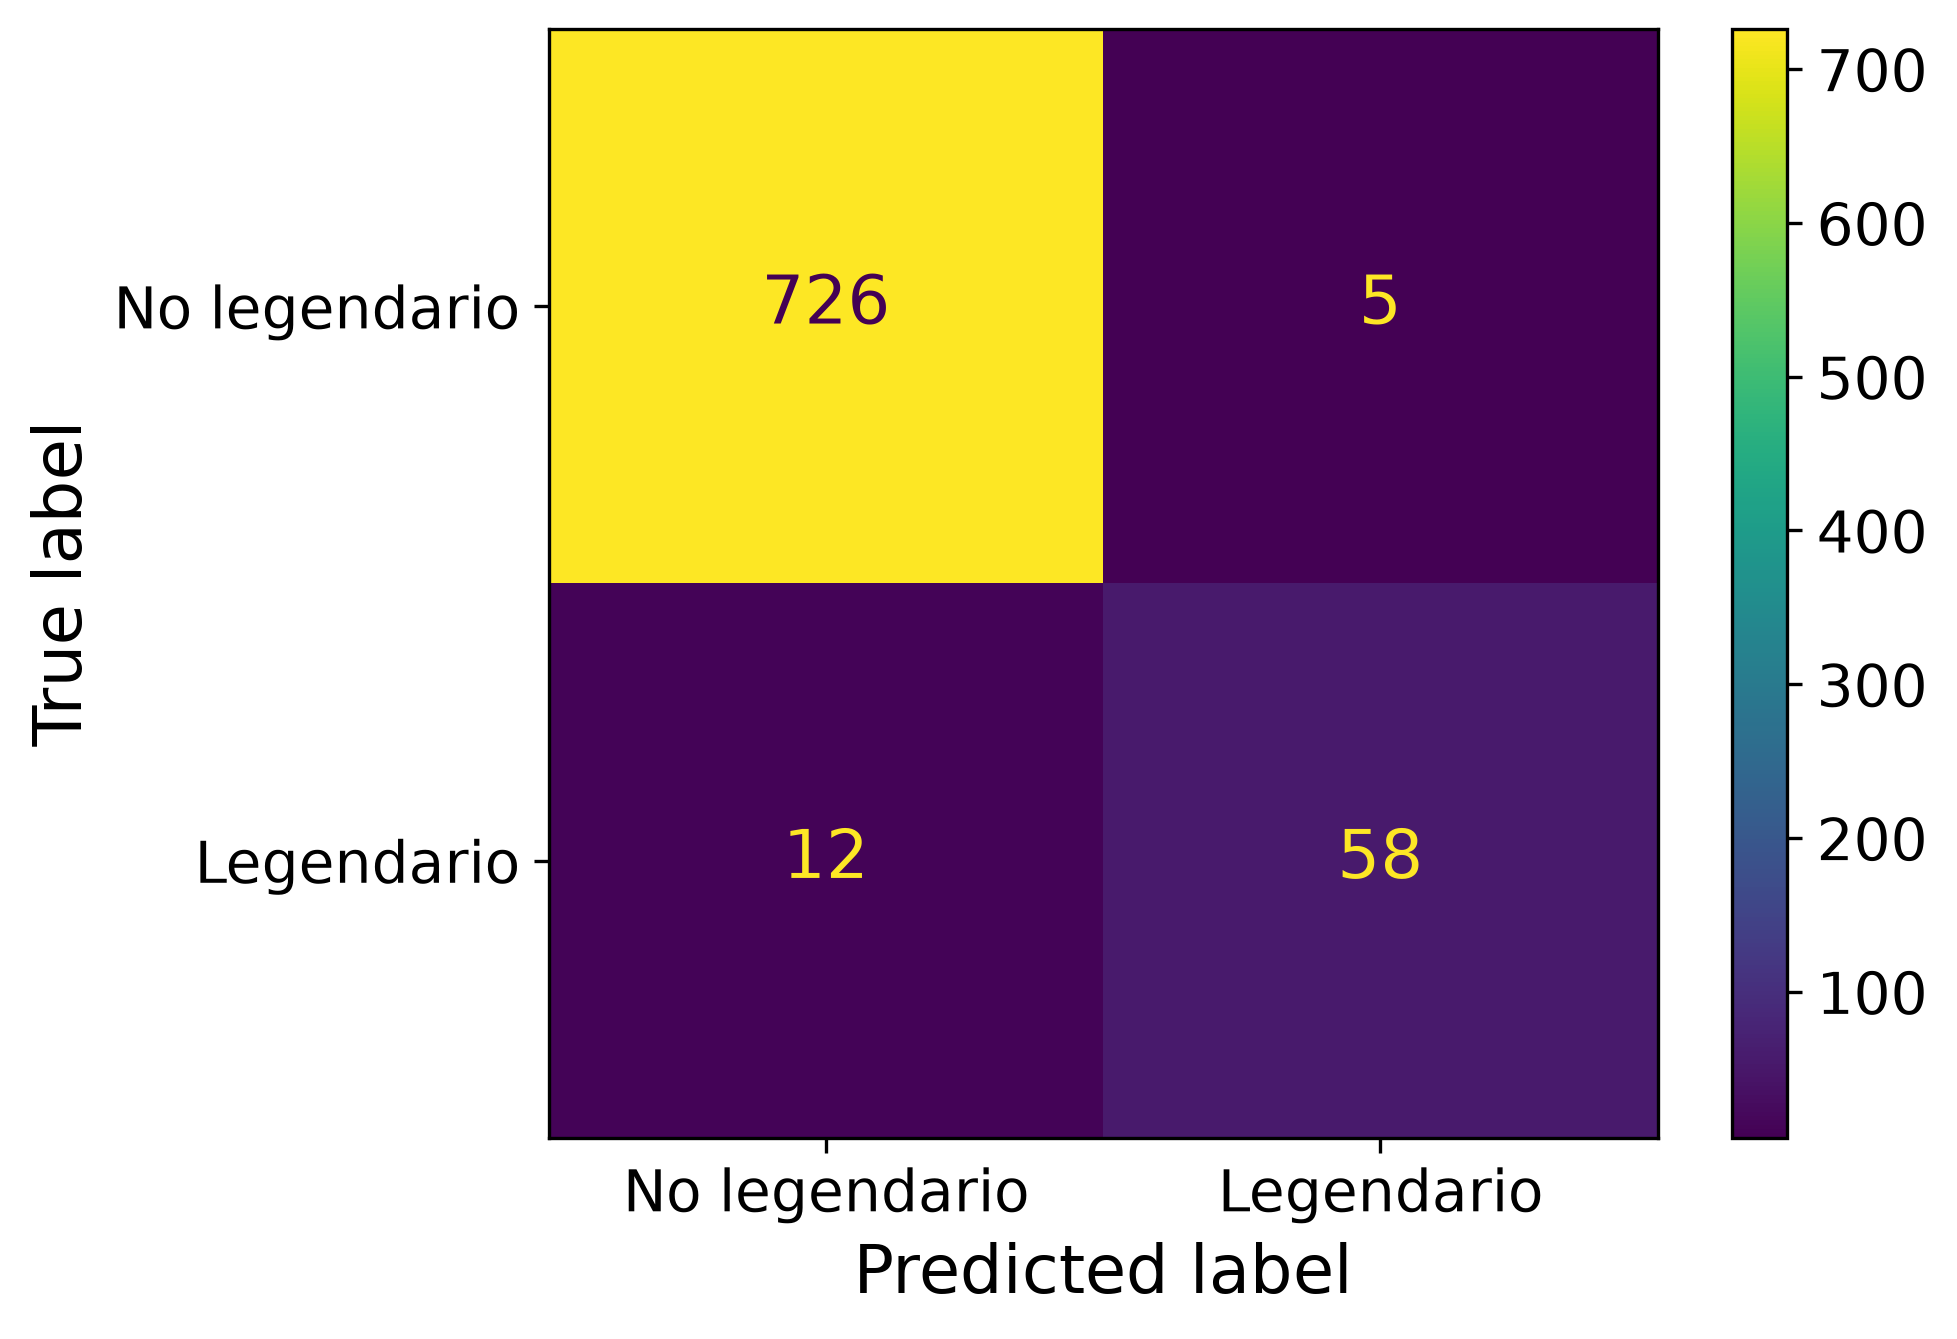

              precision    recall  f1-score   support

           0       0.98      0.99      0.99       731
           1       0.92      0.83      0.87        70

    accuracy                           0.98       801
   macro avg       0.95      0.91      0.93       801
weighted avg       0.98      0.98      0.98       801



In [ ]:
y_pred = (y_proba > 0.5).astype(int)

metrics.ConfusionMatrixDisplay.from_predictions(target, y_pred, display_labels=['No legendario', 'Legendario'])
plt.show()
print(metrics.classification_report(target, y_pred))

## Experimento: eliminar base_happiness

### Predicción

base_happiness concentra más de la mitad de la importancia del modelo, de la tarea anterior vimos que la mayoría de los no legendarios tiene un valor de 70, mientras que los legendarios pueden tomar otros valores. Se espera que al eliminar este feature del modelo, este pierda su principal criterio para separar, por lo que la métrica recall en test debería de bajar considerablemente, es decir, dejaría de detectar varios legendarios. En entrenamiento se espera que el F1 siga alto, porque un modelo de Random Forest sin límite de profundidad puede memorizar los datos de entrenamiento perfectamente. Esperamos que aumente la brecha entre train y test.

In [19]:
features_exp = features.drop(columns='base_happiness')

rf_exp = RandomForestClassifier(n_estimators=500, oob_score=True,
                                n_jobs=-1, random_state=42, **mejores_params)
rf_exp.fit(features_exp, target)

def resumen(modelo, X):
    pred_train = modelo.predict(X)
    pred_oob = (modelo.oob_decision_function_[:, 1] > 0.5).astype(int)
    return pd.DataFrame({
        'f1':        [f1_score(target, pred_train),        f1_score(target, pred_oob)],
        'precision': [precision_score(target, pred_train), precision_score(target, pred_oob)],
        'recall':    [recall_score(target, pred_train),    recall_score(target, pred_oob)]
    }, index=['train', 'test (OOB)'])

resultados_base = resumen(rf, features)
resultados_exp = resumen(rf_exp, features_exp)

pd.concat({'Con base_happiness': resultados_base,
           'Sin base_happiness': resultados_exp}).round(3)

f1  precision  recall
Con base_happiness train       1.000      1.000   1.000
                   test (OOB)  0.872      0.921   0.829
Sin base_happiness train       1.000      1.000   1.000
                   test (OOB)  0.574      0.816   0.443

In [20]:
importancias_exp = pd.Series(rf_exp.feature_importances_,
                             index=features_exp.columns).sort_values(ascending=False)
importancias_exp.head(5)

weight_kg    0.171343
speed        0.162974
sp_attack    0.151529
height_m     0.101921
hp           0.093244
dtype: float64

### Interpretación

La predicción que planteamos se cumplió. Sin base_happiness, el recall en test baja de 0.72 a 0.39, el modelo pasó de detectar 13 a solo 7 de 18 legendarios. El F1 cae a 0.52, mientras que precision no sufre un cambio significativo, el modelo se volvió más conservador, ya que predice menos legendarios pero sigue acertando en los que predice. En train el F1 se mantuvo en 1, así que la brecha entre train y test creció.

Para el caso de sin base_happiness, las features más importantes pasan a ser speed, sp_attack y weight_kg, pero los stats por sí solos no bastan, ya que muchos legendarios tienen stats parecidos a pokémon no legendarios. Esto muestra que gran parte del desempeño del modelo depende de un atributo de diseño del juego más que de características físicas del pokémon, al igual que las 4 features que eliminamos al inicio.